# Exploration et preparation

Projet pedagogique, sans usage clinique ni decision sur les etudiants.


## 1. Importer les outils

Importer les outils et trouver le dossier du projet.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)


## 2. Charger et comprendre le fichier

Charger le CSV et regarder les dimensions, les premieres lignes et les types.


In [2]:
file_path = PROJECT_ROOT / "data/raw/student_mental_health.csv"
df = pd.read_csv(file_path)
print("Lignes :", df.shape[0], "- Colonnes :", df.shape[1])
display(df.head())
df.info()


Lignes : 2000 - Colonnes : 17


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [22]:
print(df.duplicated().sum())


0


## Separer le train (80 %) et le test (20 %)

Garder 80 % pour le train et 20 % pour le test. Le test reste reserve pour la fin.


In [29]:
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

eda = X_train.copy()
eda["Mental_Health_Risk"] = y_train
risk_order = ["Low", "Medium", "High"]
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
category_columns = X_train.select_dtypes(exclude="number").columns.tolist()


## Statistiques descriptives et valeurs manquantes du train

Resumer les valeurs du train et compter les donnees manquantes.


In [23]:
missing = pd.DataFrame({
    "Nombre manquant": X_train.isna().sum(),
    "Pourcentage": X_train.isna().mean() * 100,
})
display(missing.round(2))


,Nombre manquant,Pourcentage
Age,0,0.00
Gender,0,0.00
Year_of_Study,0,0.00
Sleep_Hours,54,3.38
Study_Hours_Per_Week,0,0.00
GPA,36,2.25
Social_Media_Hours,48,3.00
Screen_Time_Hours,0,0.00
Physical_Activity,0,0.00
Financial_Stress,76,4.75


## Distribution de la cible et desequilibre

Les classes sont proches de 34 %, 33 %, 33 % : pas besoin de SMOTE ici.


In [27]:
class_counts = y_train.value_counts().reindex(risk_order, fill_value=0)
class_summary = pd.DataFrame({
    "Effectif": class_counts,
    "Pourcentage": class_counts / len(y_train) * 100,
})
display(class_summary.round(2))


,Effectif,Pourcentage
Mental_Health_Risk,,
Low,528,33.0
Medium,528,33.0
High,544,34.0


## Heures de la semaine

Hypothese a confirmer : sommeil, ecran et reseaux sont en h/jour. Multiplier par 7. La somme est indicative car les activites peuvent se chevaucher ; ne pas rajouter les reseaux au temps ecran.


In [32]:
eda["Sleep_Week"] = eda["Sleep_Hours"] * 7
eda["Screen_Week"] = eda["Screen_Time_Hours"] * 7
eda["Social_Week"] = eda["Social_Media_Hours"] * 7
eda["Weekly_Sum_Indicative"] = eda["Sleep_Week"] + eda["Screen_Week"] + eda["Study_Hours_Per_Week"]
weekly_columns = ["Sleep_Week", "Screen_Week", "Social_Week", "Study_Hours_Per_Week", "Weekly_Sum_Indicative"]
display(eda[weekly_columns].describe().round(2))

social_above_screen = eda["Social_Media_Hours"] > eda["Screen_Time_Hours"]
sum_above_week = eda["Weekly_Sum_Indicative"] > 168
print("Reseaux > ecran :", social_above_screen.sum(), "cas a verifier")
print("Somme indicative > 168 h :", sum_above_week.sum(), "cas a examiner")


,Sleep_Week,Screen_Week,Social_Week,Study_Hours_Per_Week,Weekly_Sum_Indicative
count,1546.00,1600.00,1552.00,1600.00,1546.00
mean,47.26,60.04,42.25,19.98,127.33
std,7.86,11.61,7.94,5.77,13.78
min,25.20,23.10,14.70,2.40,88.50
25%,42.00,51.80,37.10,16.00,117.80
50%,46.90,59.50,42.00,19.80,127.50
75%,52.50,67.90,47.60,24.00,136.67
max,70.00,98.00,70.00,38.30,170.20


Reseaux > ecran : 27 cas a verifier
Somme indicative > 168 h : 2 cas a examiner


##  Age et annee universitaire

Comparer les ages par annee. Ne pas corriger un age uniquement parce que le parcours semble inhabituel.


,count,min,median,max
Year_of_Study,,,,
1,416,17,21.0,26
2,393,17,21.0,28
3,335,17,21.0,27
4,295,17,21.0,28
5,161,17,21.0,26


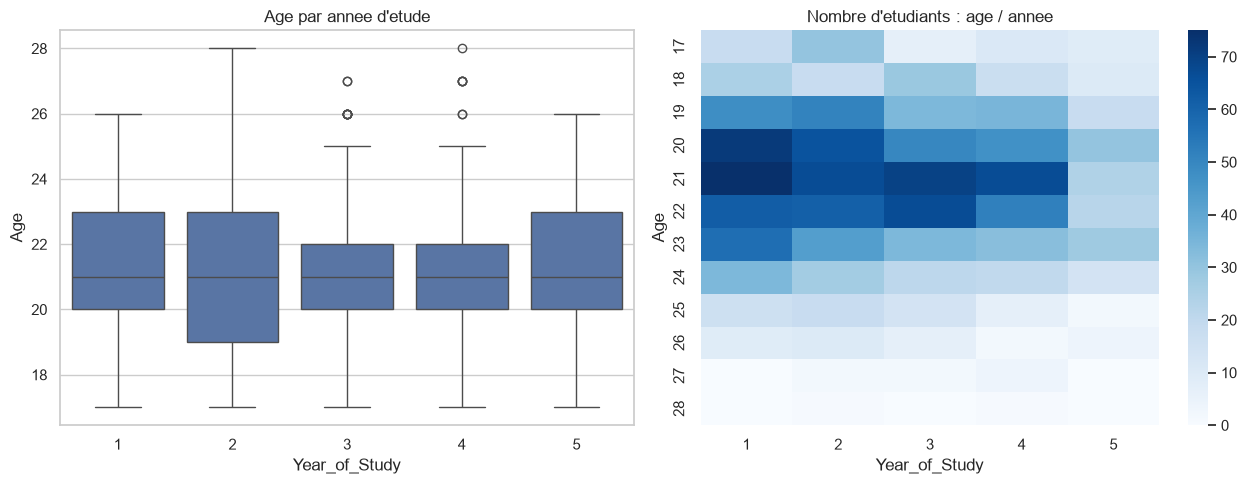

In [9]:
display(eda.groupby("Year_of_Study")["Age"].agg(["count", "min", "median", "max"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=eda, x="Year_of_Study", y="Age", ax=axes[0])
axes[0].set_title("Age par annee d'etude")
age_year = pd.crosstab(eda["Age"], eda["Year_of_Study"])
sns.heatmap(age_year, cmap="Blues", ax=axes[1])
axes[1].set_title("Nombre d'etudiants : age / annee")
plt.tight_layout()
plt.show()


##  Nombres et classes de risque

Comparer les medianes et les distributions selon la classe. Association ne veut pas dire causalite.


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Mental_Health_Risk,,,,,,,,,,
Low,21.0,3.0,7.6,21.7,2.71,5.8,8.2,5.1,7.3,86.3
Medium,21.0,2.0,6.7,20.0,2.54,5.9,8.4,6.0,6.7,85.6
High,21.0,2.0,6.0,17.9,2.43,6.4,9.0,6.9,5.9,83.8


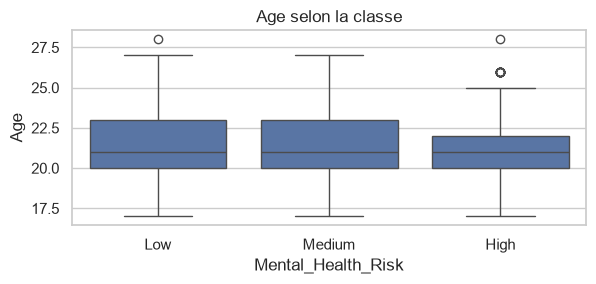

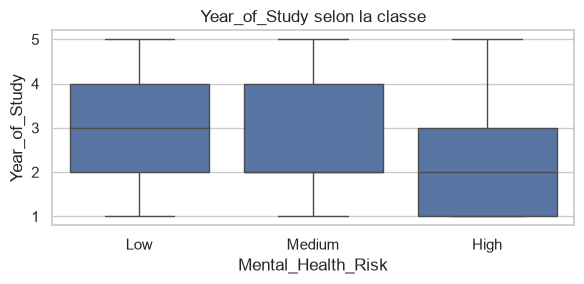

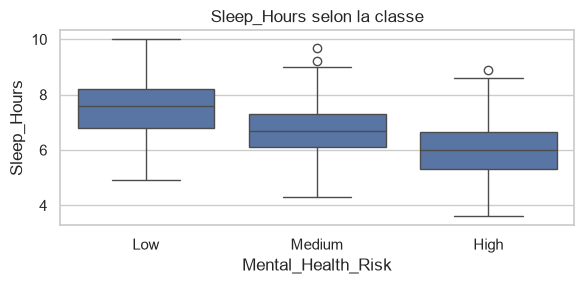

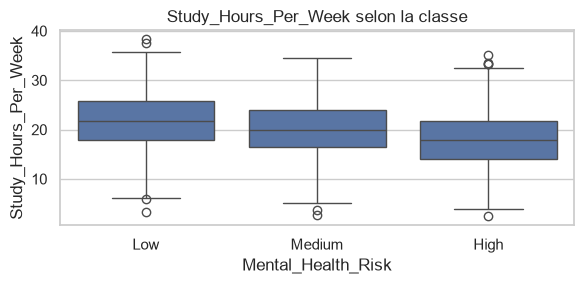

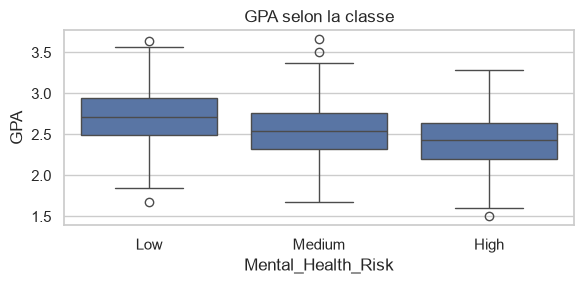

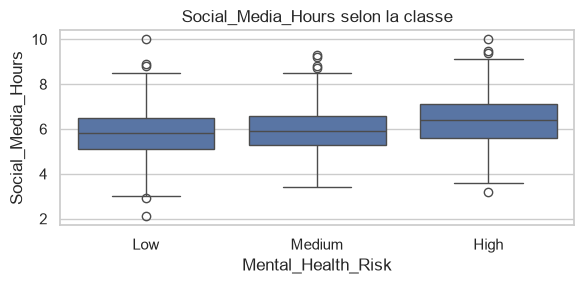

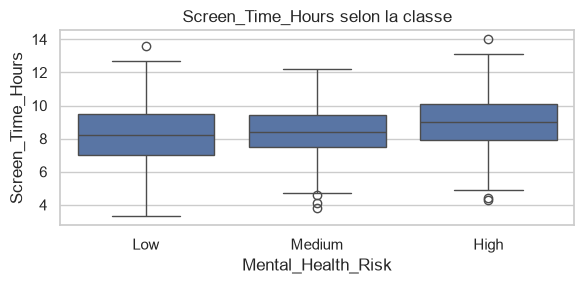

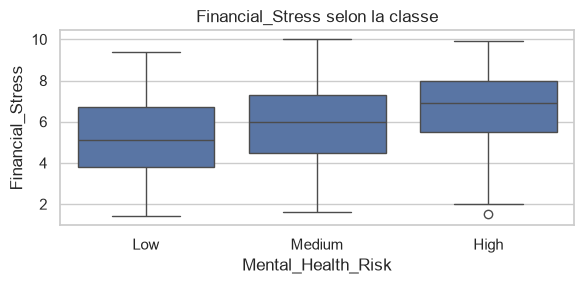

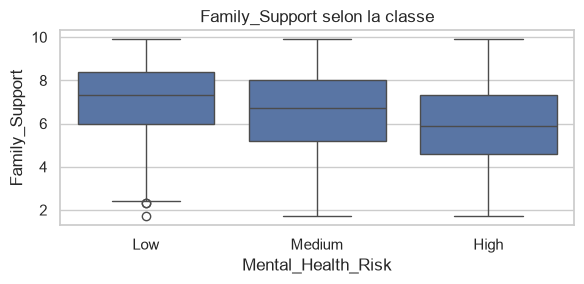

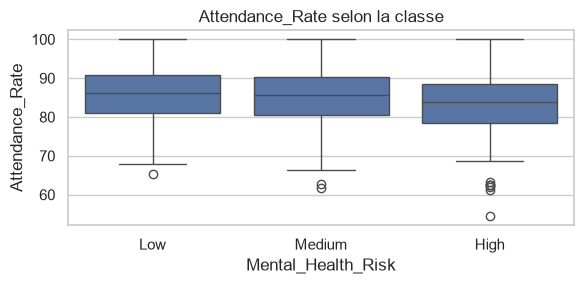

In [10]:
display(eda.groupby("Mental_Health_Risk")[numeric_columns].median().reindex(risk_order).round(2))
for column in numeric_columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=eda, x="Mental_Health_Risk", y=column, order=risk_order)
    plt.title(column + " selon la classe")
    plt.tight_layout()
    plt.show()


## Categories et classes de risque

Afficher les pourcentages de classes dans chaque categorie avec les effectifs.


Variable : Gender


,Effectif,Low,Medium,High
Gender,,,,
Female,779,33.0,32.0,35.0
Male,746,32.3,34.7,33.0
Non-binary,75,40.0,26.7,33.3


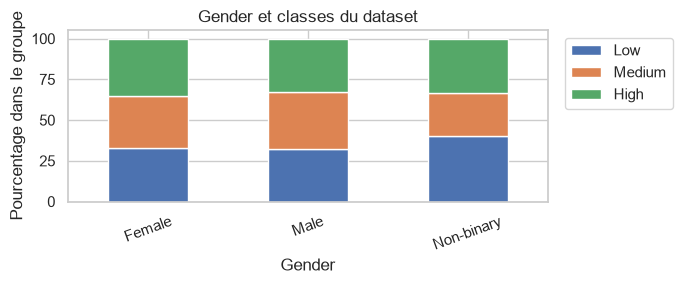

Variable : Physical_Activity


,Effectif,Low,Medium,High
Physical_Activity,,,,
High,319,49.5,30.1,20.4
Low,539,23.9,31.9,44.2
Moderate,742,32.5,35.0,32.5


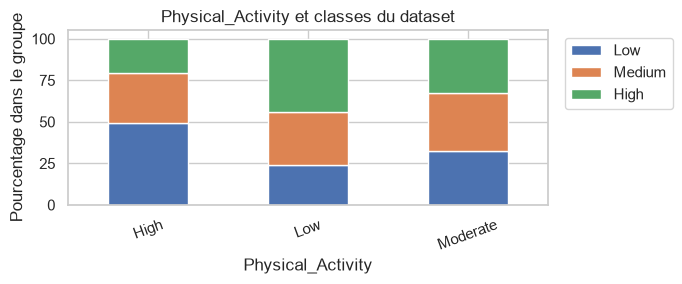

Variable : Part_Time_Job


,Effectif,Low,Medium,High
Part_Time_Job,,,,
No,1029,36.6,33.4,29.9
Yes,571,26.4,32.2,41.3


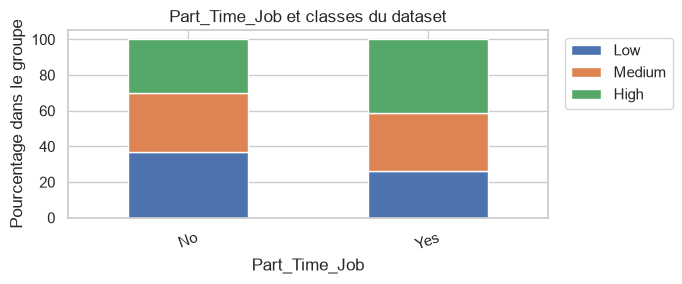

Variable : Diet_Quality


,Effectif,Low,Medium,High
Diet_Quality,,,,
Average,687,33.5,33.2,33.3
Good,382,41.4,31.7,27.0
Manquant,55,34.5,32.7,32.7
Poor,476,25.4,33.8,40.8


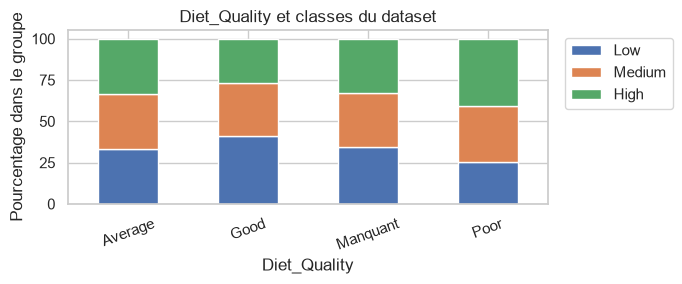

Variable : Previous_Mental_Health_History


,Effectif,Low,Medium,High
Previous_Mental_Health_History,,,,
No,1140,38.7,33.1,28.2
Yes,460,18.9,32.8,48.3


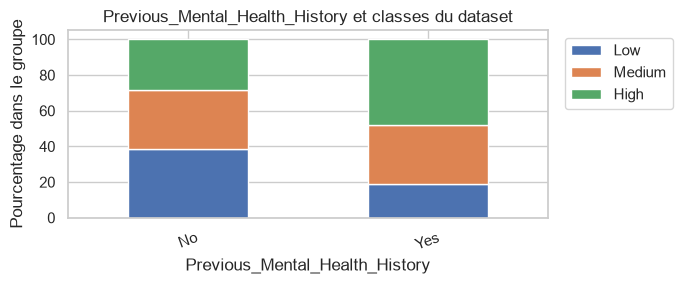

In [11]:
category_ranking = []
for column in category_columns:
    groups = eda[column].astype("object").fillna("Manquant")
    counts = pd.crosstab(groups, y_train).reindex(columns=risk_order, fill_value=0)
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    print("Variable :", column)
    display(counts.sum(axis=1).rename("Effectif").to_frame().join(percentages.round(1)))
    percentages.plot(kind="bar", stacked=True, figsize=(7, 3))
    plt.title(column + " et classes du dataset")
    plt.ylabel("Pourcentage dans le groupe")
    plt.xticks(rotation=20)
    plt.legend(bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

    present_groups = percentages.drop(index="Manquant", errors="ignore")
    gap = present_groups["High"].max() - present_groups["High"].min()
    category_ranking.append({"Variable": column, "Ecart High en points": gap})


## 12. Correlations entre variables explicatives

Regarder les correlations entre nombres et quelques nuages de points.


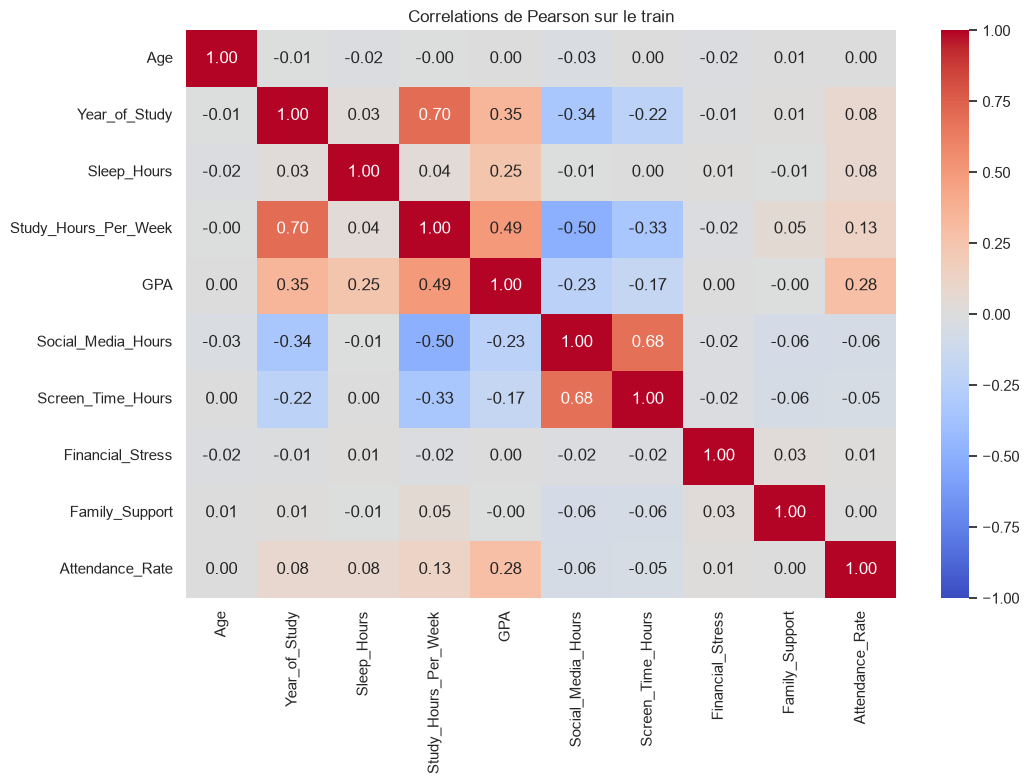

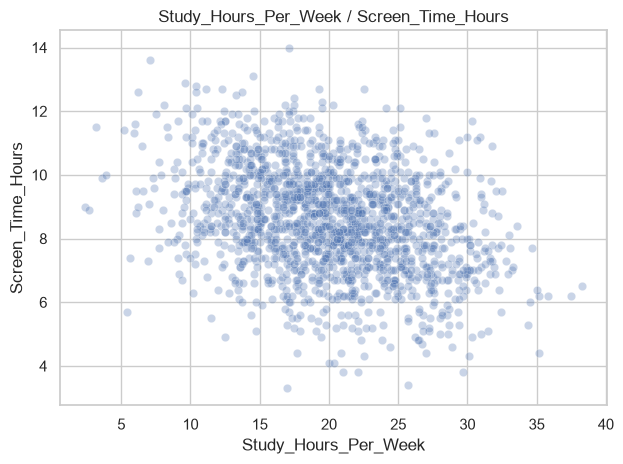

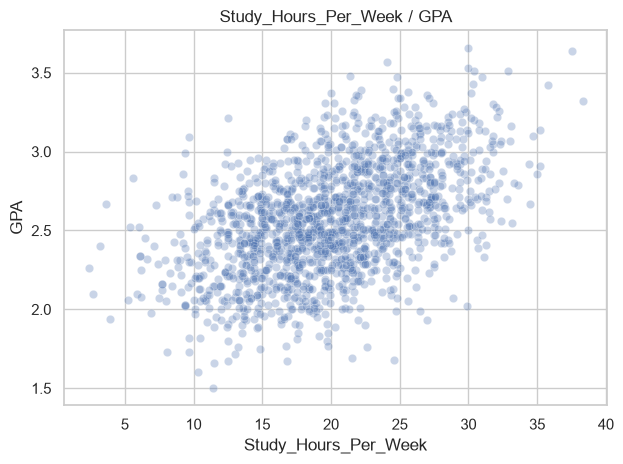

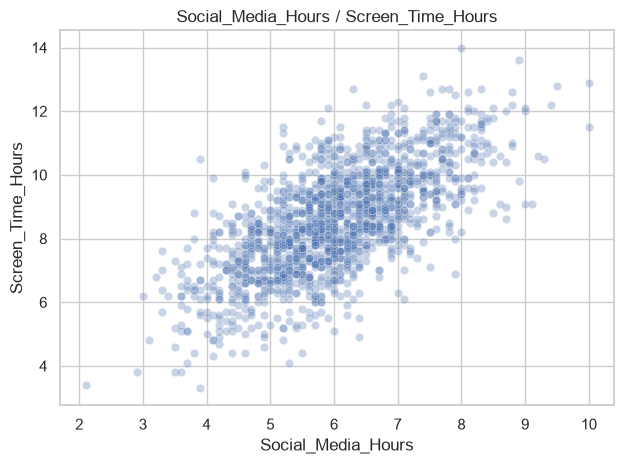

In [12]:
correlations = X_train[numeric_columns].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlations de Pearson sur le train")
plt.tight_layout()
plt.show()

pairs = [("Study_Hours_Per_Week", "Screen_Time_Hours"),
         ("Study_Hours_Per_Week", "GPA"),
         ("Social_Media_Hours", "Screen_Time_Hours")]
for first, second in pairs:
    sns.scatterplot(data=eda, x=first, y=second, alpha=0.3)
    plt.title(first + " / " + second)
    plt.tight_layout()
    plt.show()


## 13. Variables les plus associees a la cible

Classer les nombres par Spearman et les categories par ecart de proportion High. Ces deux scores ne sont pas directement comparables.


In [13]:
risk_numbers = y_train.map({"Low": 0, "Medium": 1, "High": 2})
number_ranking = []
for column in numeric_columns:
    coefficient = X_train[column].corr(risk_numbers, method="spearman")
    number_ranking.append({
        "Variable": column,
        "Spearman": coefficient,
        "Force absolue": abs(coefficient),
        "Valeurs presentes": X_train[column].notna().sum(),
    })
number_ranking = pd.DataFrame(number_ranking).sort_values("Force absolue", ascending=False)
category_ranking = pd.DataFrame(category_ranking).sort_values("Ecart High en points", ascending=False)
display(number_ranking.round(3))
display(category_ranking.round(2))
print("Premiers facteurs numeriques a discuter :", number_ranking["Variable"].head(3).tolist())


,Variable,Spearman,Force absolue,Valeurs presentes
2,Sleep_Hours,-0.548,0.548,1546
4,GPA,-0.347,0.347,1564
7,Financial_Stress,0.309,0.309,1524
3,Study_Hours_Per_Week,-0.255,0.255,1600
8,Family_Support,-0.238,0.238,1564
5,Social_Media_Hours,0.210,0.210,1552
6,Screen_Time_Hours,0.184,0.184,1600
1,Year_of_Study,-0.168,0.168,1600
9,Attendance_Rate,-0.134,0.134,1561
0,Age,0.003,0.003,1600


,Variable,Ecart High en points
1,Physical_Activity,23.78
4,Previous_Mental_Health_History,20.02
3,Diet_Quality,13.79
2,Part_Time_Job,11.40
0,Gender,2.07


Premiers facteurs numeriques a discuter : ['Sleep_Hours', 'GPA', 'Financial_Stress']


## Detecter les valeurs extremes avec IQR

IQR = Q3 - Q1. Les bornes sont Q1 - 1.5 x IQR et Q3 + 1.5 x IQR. Extreme ne signifie pas forcement faux.


In [35]:
from src.pipeline import OUTLIER_COLUMNS

outlier_rows = []
for column in OUTLIER_COLUMNS:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = 0
    if iqr > 0:
        count = ((X_train[column] < lower) | (X_train[column] > upper)).sum()
    outlier_rows.append({"Variable": column, "lower ..": lower,
                         "upper ": upper, "count": count})
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))


,Variable,lower ..,upper,count
0,Sleep_Hours,3.75,9.75,9
1,Study_Hours_Per_Week,4.00,36.00,7
2,GPA,1.60,3.52,5
3,Social_Media_Hours,3.05,9.05,10
4,Screen_Time_Hours,3.95,13.15,7
5,Financial_Stress,0.15,11.75,0
6,Family_Support,1.00,12.20,0
7,Attendance_Rate,65.35,104.95,10


## Preparer avec un pipeline unique

Pipeline : bornage IQR, imputation mediane/mode, standardisation et OneHotEncoder. Apprendre sur le train seulement. Le bornage reste un choix a evaluer.


In [37]:
from src.pipeline import build_preprocessor

preprocessor = build_preprocessor(X_train, use_outliers=True)
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

